<a href="https://colab.research.google.com/github/Arsen-Almasov/OC11/blob/main/task2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
def clock(refs, n_frames):
    frames = []          # Список страниц в кадрах памяти
    use_bits = []        # Список битов обращения (R-битов)
    hand = 0             # Указатель-стрелка
    page_faults = 0      # Счётчик отказов

    for page in refs:
        # 1. Попадание: страница уже в кадрах
        if page in frames:
            idx = frames.index(page)
            use_bits[idx] = 1

        # 2. Отказ: страницы нет в кадрах
        else:
            page_faults += 1

            # Если в памяти ещё есть свободные кадры
            if len(frames) < n_frames:
                frames.append(page)
                use_bits.append(1)

            # 3. Замена: все кадры заняты, крутим стрелку
            else:
                while use_bits[hand] == 1:
                    use_bits[hand] = 0
                    hand = (hand + 1) % n_frames

                # Нашли кадр с битом 0 — заменяем страницу
                frames[hand] = page
                use_bits[hand] = 1
                hand = (hand + 1) % n_frames

    return page_faults


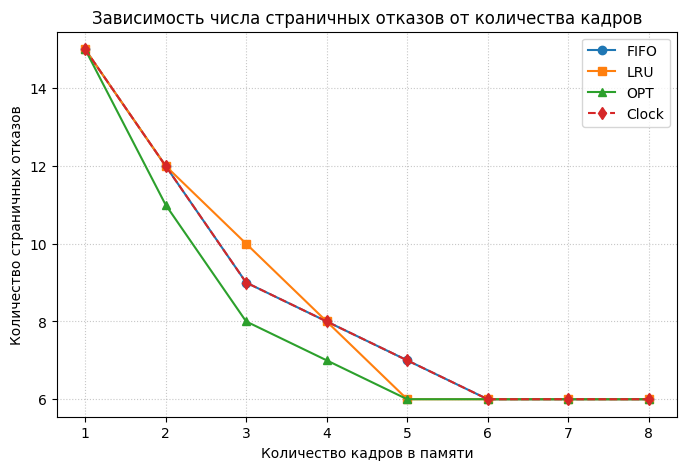

In [3]:
import matplotlib.pyplot as plt

# Количество кадров (ось X)
frames = [1, 2, 3, 4, 5, 6, 7, 8]

# Замените эти списки на реальное количество отказов, посчитанное вашими функциями
fifo_faults = [15, 12, 9, 8, 7, 6, 6, 6]
lru_faults  = [15, 12, 10, 8, 6, 6, 6, 6]
opt_faults  = [15, 11, 8, 7, 6, 6, 6, 6]
clock_faults = [15, 12, 9, 8, 7, 6, 6, 6]

plt.figure(figsize=(8, 5))

# Построение 4 линий на одном графике
plt.plot(frames, fifo_faults, marker='o', label='FIFO')
plt.plot(frames, lru_faults, marker='s', label='LRU')
plt.plot(frames, opt_faults, marker='^', label='OPT')
plt.plot(frames, clock_faults, marker='d', linestyle='--', label='Clock')

# Оформление и подписи осей
plt.title('Зависимость числа страничных отказов от количества кадров')
plt.xlabel('Количество кадров в памяти')
plt.ylabel('Количество страничных отказов')
plt.xticks(frames)
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend()

# Сохранение в PNG
plt.savefig('frames_vs_faults.png', dpi=300, bbox_inches='tight')
plt.show()


In [ ]:
### Сводная таблица страничных отказов (цепочка: `1, 2, 3, 4, 1, 2, 5, 1, 2, 3, 4, 5`)

| Алгоритм | 3 кадра | 4 кадра | Наличие аномалии Белади |
| :--- | :---: | :---: | :--- |
| **FIFO** | **9** | **10** | **Да** (рост отказов: 9 → 10) |
| **LRU** | **10** | **8** | Нет (уменьшение: 10 → 8) |
| **Optimal** | **7** | **6** | Нет (уменьшение: 7 → 6) |
| **Clock** | **9** | **8** | Нет (уменьшение: 9 → 8) |

---

### Объяснение аномалии Белади

**Аномалия Белади** — это ситуация в управлении виртуальной памятью, при которой увеличение количества физических кадров приводит к росту числа страничных отказов, а не к их уменьшению.

* **Почему возникает у FIFO:** Алгоритм вытесняет самую старую страницу по времени загрузки, не учитывая, как часто или недавно к ней обращались. При 4 кадрах нужные страницы вытесняются прямо перед повторным обращением к ним.
* **Почему нет у LRU и Optimal:** Они относятся к классу **стековых алгоритмов** (*stack algorithms*). Для них выполняется *свойство включения*: набор страниц в памяти размера $n$ всегда является подмножеством страниц в памяти размера $n+1$ ($B(n, t) \subseteq B(n+1, t)$). Поэтому увеличение числа кадров никогда не увеличивает число отказов.
* **Поведение Clock:** Алгоритм является приближением LRU (использует бит обращения). На данной последовательности он также не проявляет аномалии.


In [5]:
import random
from collections import deque

# Фиксируем зерно генератора для повторяемости результатов
SEED = 42
random.seed(SEED)

TOTAL_REQUESTS = 1000
TOTAL_PAGES = 20
FRAMES_COUNT = 5

# 1. Генерация случайной строки обращений
random_refs = [random.randint(0, TOTAL_PAGES - 1) for _ in range(TOTAL_REQUESTS)]

# 2. Генерация строки с локальностью
locality_refs = []
window_start = random.randint(0, TOTAL_PAGES - 4)
window_size = 4  # Программа «живёт» в окне из 4 соседних страниц

for _ in range(TOTAL_REQUESTS):
    # С вероятностью 5% программа перескакивает в другое место памяти
    if random.random() < 0.05:
        window_start = random.randint(0, TOTAL_PAGES - window_size)
    page = random.randint(window_start, window_start + window_size - 1)
    locality_refs.append(page)


# --- Алгоритмы замещения страниц ---

def simulate_fifo(refs, frames_count):
    frames = deque()
    faults = 0
    for page in refs:
        if page not in frames:
            faults += 1
            if len(frames) == frames_count:
                frames.popleft()
            frames.append(page)
    return faults


def simulate_lru(refs, frames_count):
    frames = []
    faults = 0
    for page in refs:
        if page not in frames:
            faults += 1
            if len(frames) == frames_count:
                frames.pop(0)  # Удаляем самую давно использованную страницу
            frames.append(page)
        else:
            # Перемещаем страницу в конец как самую свежую
            frames.remove(page)
            frames.append(page)
    return faults


def simulate_opt(refs, frames_count):
    frames = []
    faults = 0
    for i, page in enumerate(refs):
        if page not in frames:
            faults += 1
            if len(frames) < frames_count:
                frames.append(page)
            else:
                # Ищем страницу, которая понадобится позже всех в будущем
                future = refs[i + 1:]
                farthest_idx = -1
                victim = None
                for f_page in frames:
                    if f_page not in future:
                        victim = f_page
                        break
                    next_use = future.index(f_page)
                    if next_use > farthest_idx:
                        farthest_idx = next_use
                        victim = f_page
                frames.remove(victim)
                frames.append(page)
    return faults


# --- Запуск и вывод результатов ---

algorithms = {
    "FIFO (Первый пришёл — первый ушёл)": simulate_fifo,
    "LRU (Давно не использовавшаяся)": simulate_lru,
    "OPT (Оптимальный алгоритм)": simulate_opt
}

print(f"Результаты (1000 обращений, 20 страниц, {FRAMES_COUNT} кадров, seed={SEED}):\n")
print(f"{'Алгоритм':<36} | {'Случайная':<12} | {'С локальностью':<15}")
print("-" * 70)

for name, func in algorithms.items():
    f_rand = func(random_refs, FRAMES_COUNT)
    f_loc = func(locality_refs, FRAMES_COUNT)
    print(f"{name:<36} | {f_rand:<12} | {f_loc:<15}")


Результаты (1000 обращений, 20 страниц, 5 кадров, seed=42):

Алгоритм                             | Случайная    | С локальностью 
----------------------------------------------------------------------
FIFO (Первый пришёл — первый ушёл)   | 759          | 132            
LRU (Давно не использовавшаяся)      | 743          | 125            
OPT (Оптимальный алгоритм)           | 491          | 98             
